<a href="https://colab.research.google.com/github/Al-harithM/cats-vs-dogs-cnn/blob/main/cats_vs_dogs_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torchvision
from torchvision.transforms import transforms
from torch.utils.data import Dataset

In [3]:
# Convert to tensors and normalize
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
])

In [5]:
transforms_augmented = transforms.Compose([
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.RandomCrop(32, padding=4),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
# Download cifar-10 training dataset
trainset = torchvision.datasets.CIFAR10(
    root='/content/drive/MyDrive/cifar_data',
    train=True,
    download=True,
    transform=transform
)

CAT_LABEL = 3
dog_label = 5
target_classes = [CAT_LABEL, dog_label]

100%|██████████| 170M/170M [23:24<00:00, 121kB/s]


In [9]:
augmented_dataset = torchvision.datasets.CIFAR10(
    root='/content/drive/MyDrive/cifar_data',
    train=True,
    download=True,
    transform=transforms_augmented
)

CAT_LABEL = 3
dog_label = 5
target_classes = [CAT_LABEL, dog_label]

In [10]:
def get_underlying_targets(dataset):
    # Recursively traverse wrappers (Subset, Custom Subsets) to find the original targets list
    if hasattr(dataset, 'targets'):
        return dataset.targets
    elif hasattr(dataset, 'dataset'):
        return get_underlying_targets(dataset.dataset)
    elif hasattr(dataset, 'base_dataset'):
        return get_underlying_targets(dataset.base_dataset)
    else:
        raise AttributeError("Could not find 'targets' in the dataset hierarchy.")

train_targets = get_underlying_targets(trainset)
indices = [i for i, target in enumerate(train_targets) if target in target_classes]

class CIFAR10BinarySubset(Dataset):
    def __init__(self, base_dataset, indices):
        self.base_dataset = base_dataset
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        # Fetch the original image and label using our filtered index list
        orig_idx = self.indices[idx]
        image, label = self.base_dataset[orig_idx]

        # Remap: Cat (3) becomes 0, Dog (5) becomes 1
        new_label = 0 if label == CAT_LABEL else 1

        return image, new_label

# Instantiate your clean, filtered binary dataset
binary_trainset = CIFAR10BinarySubset(trainset, indices)

print(f"Original dataset size: {len(trainset)} images")
print(f"Filtered binary dataset size (Cats & Dogs only): {len(binary_trainset)} images")

# Quick verification of a single sample
sample_image, sample_label = binary_trainset[0]
print(f"Sample Image Shape: {sample_image.shape}")
print(f"Remapped Label (0 for cat, 1 for dog): {sample_label}")

Original dataset size: 50000 images
Filtered binary dataset size (Cats & Dogs only): 10000 images
Sample Image Shape: torch.Size([3, 32, 32])
Remapped Label (0 for cat, 1 for dog): 0


In [11]:
augmented_binary_trainset = CIFAR10BinarySubset(augmented_dataset, indices)

print(f"Original dataset size: {len(augmented_dataset)} images")
print(f"Filtered binary dataset size (Cats & Dogs only): {len(augmented_binary_trainset)} images")

Original dataset size: 50000 images
Filtered binary dataset size (Cats & Dogs only): 10000 images


In [12]:
trainingset, testingset = torch.utils.data.random_split(binary_trainset,[0.6,0.4])


In [13]:
complete_train_dataset = torch.utils.data.ConcatDataset(
    [trainingset, augmented_binary_trainset])

In [14]:
batch_size = 64

trainloader = torch.utils.data.DataLoader(complete_train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
testloader  = torch.utils.data.DataLoader(testingset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

print(f"Training dataset size = {len(complete_train_dataset)}")
print(f"Testing set size = {len(testingset)}")

classes = ('cat', 'dog')


Training dataset size = 16000
Testing set size = 4000


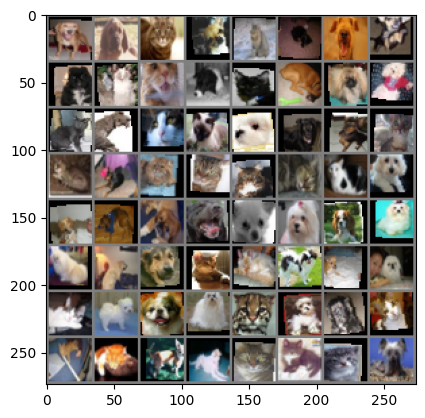

In [15]:
#show some images
import matplotlib.pyplot as plt
import numpy as np

def imshow(img):
  img = img/2 + 0.5 #unnormalize
  npimg = img.numpy()
  plt.imshow(np.transpose(npimg,(1,2,0)))
  plt.show

#get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

#show images
imshow(torchvision.utils.make_grid(images))



# Define the Convolutional Neural Network

In [94]:
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
  def __init__(self):
    super().__init__()

    self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
    self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
    self.conv3 = nn.Conv2d(64, 128, 3, padding=1)

    self.batchNorm1 = nn.BatchNorm2d(32)
    self.batchNorm2 = nn.BatchNorm2d(64)
    self.batchNorm3 = nn.BatchNorm2d(128)

    self.pool = nn.MaxPool2d(2, 2)

    # CIFAR-10 starts as 32x32. After 3 pooling operations:
    # 32x32 -> 16x16 -> 8x8 -> 4x4
    self.fc1 = nn.Linear(128 * 4 * 4, 120)
    self.fc2 = nn.Linear(120, 84)
    self.fc3 = nn.Linear(84, 2)

  def forward(self, x):
    x = self.pool(F.relu(self.batchNorm1(self.conv1(x))))
    x = self.pool(F.relu(self.batchNorm2(self.conv2(x))))
    x = self.pool(F.relu(self.batchNorm3(self.conv3(x))))

    x = torch.flatten(x, 1)
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    x = self.fc3(x)
    return x

net = Net()

# Define the Loss Function and Optimizer

In [95]:
import torch.optim as optim
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr = 0.001, momentum = 0.9)

# Train the Network (CPU)

In [82]:
for epoch in range(10): #Loop over the dataset multiple times
  running_loss = 0.0
  for i, data in enumerate(trainloader, 0):
    #get the inputs; data is a list of [imputs, labels]
    inputs, labels = data
    #zero the parameters gradients
    optimizer.zero_grad()
    #forward + backward + optimize
    outputs = net(inputs)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()
    #print Statistics
    running_loss += loss.item()
    if i % 50 == 49: #print every 50 mini batches
      print(f'[{epoch + 1}, {i +1:5d}] loss: {running_loss / 50:.3f}')
      running_loss = 0.0

print("Finished Training")

[1,    50] loss: 0.702
[1,   100] loss: 0.698
[1,   150] loss: 0.696
[1,   200] loss: 0.699
[1,   250] loss: 0.697
[2,    50] loss: 0.697
[2,   100] loss: 0.698
[2,   150] loss: 0.697
[2,   200] loss: 0.697
[2,   250] loss: 0.702
[3,    50] loss: 0.698
[3,   100] loss: 0.699
[3,   150] loss: 0.697
[3,   200] loss: 0.697
[3,   250] loss: 0.701
[4,    50] loss: 0.697
[4,   100] loss: 0.700
[4,   150] loss: 0.698
[4,   200] loss: 0.700
[4,   250] loss: 0.697
[5,    50] loss: 0.695
[5,   100] loss: 0.700
[5,   150] loss: 0.698
[5,   200] loss: 0.699
[5,   250] loss: 0.699
[6,    50] loss: 0.701
[6,   100] loss: 0.699
[6,   150] loss: 0.700
[6,   200] loss: 0.696
[6,   250] loss: 0.696
[7,    50] loss: 0.698
[7,   100] loss: 0.697
[7,   150] loss: 0.699
[7,   200] loss: 0.701
[7,   250] loss: 0.697
[8,    50] loss: 0.697
[8,   100] loss: 0.698
[8,   150] loss: 0.700
[8,   200] loss: 0.697
[8,   250] loss: 0.701
[9,    50] loss: 0.698
[9,   100] loss: 0.699
[9,   150] loss: 0.700
[9,   200] 

In [83]:
PATH = './cifar_net.pt'
torch.save(net.state_dict(), PATH)

# Train the network on GPU

In [96]:
device = torch.device(torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cuda


In [97]:
net = Net()
net.to(device)

Net(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batchNorm1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batchNorm2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batchNorm3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=2, bias=True)
)

In [116]:
import torch.optim as optim

# Ensure the model is on the target device (GPU)
net.to(device)

# Re-initialize the optimizer with the GPU model parameters
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)
criterion = nn.CrossEntropyLoss()

# Train for 15 epochs to ensure convergence
for epoch in range(15):
  running_loss = 0.0
  for i, data in enumerate(trainloader, 0):
    inputs, labels = data
    # Move inputs and labels to GPU
    inputs, labels = inputs.to(device), labels.to(device)

    optimizer.zero_grad()

    outputs = net(inputs)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    if i % 50 == 49:
      print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 50:.3f}')
      running_loss = 0.0

  print(f"Finished Training for epoch = {epoch + 1}")

[1,    50] loss: 0.289
[1,   100] loss: 0.269
[1,   150] loss: 0.268
[1,   200] loss: 0.287
[1,   250] loss: 0.289
Finished Training for epoch = 1
[2,    50] loss: 0.281
[2,   100] loss: 0.275
[2,   150] loss: 0.266
[2,   200] loss: 0.284
[2,   250] loss: 0.290
Finished Training for epoch = 2
[3,    50] loss: 0.254
[3,   100] loss: 0.276
[3,   150] loss: 0.269
[3,   200] loss: 0.280
[3,   250] loss: 0.317
Finished Training for epoch = 3
[4,    50] loss: 0.256
[4,   100] loss: 0.270
[4,   150] loss: 0.275
[4,   200] loss: 0.277
[4,   250] loss: 0.291
Finished Training for epoch = 4
[5,    50] loss: 0.283
[5,   100] loss: 0.262
[5,   150] loss: 0.257
[5,   200] loss: 0.276
[5,   250] loss: 0.246
Finished Training for epoch = 5
[6,    50] loss: 0.242
[6,   100] loss: 0.261
[6,   150] loss: 0.280
[6,   200] loss: 0.270
[6,   250] loss: 0.254
Finished Training for epoch = 6
[7,    50] loss: 0.252
[7,   100] loss: 0.267
[7,   150] loss: 0.261
[7,   200] loss: 0.275
[7,   250] loss: 0.272
Fin

In [117]:
PATH = './cifar_net.pt'
torch.save(net.state_dict(), PATH)

# Test the Network

GroundTruth:  dog   dog   cat   cat   cat   dog   dog   dog   dog   cat  


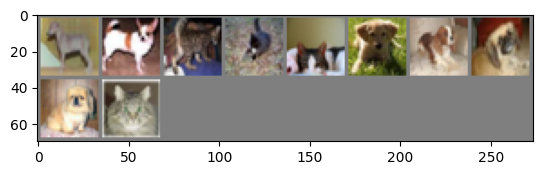

In [118]:
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images[:10]))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(10)))

In [119]:
net = Net()
net.load_state_dict(torch.load(PATH, weights_only=True))

# 1. ALWAYS set the model to evaluation mode after loading weights
net.eval()

# 2. Ensure it is moved to the target device (GPU)
net.to(device)

Net(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batchNorm1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batchNorm2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batchNorm3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=2, bias=True)
)

In [120]:
outputs = net(images)

RuntimeError: Input type (torch.FloatTensor) and weight type (torch.cuda.FloatTensor) should be the same or input should be a MKLDNN tensor and weight is a dense tensor

In [121]:
_, predicted = torch.max(outputs, 1)
print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}' for j in range(10)))

Predicted:  dog   cat   dog   dog   cat   cat   cat   cat   dog   cat  


In [122]:
correct = 0
total = 0

# Ensure the model is moved to the GPU for evaluation
net.to(device)

with torch.no_grad():
  for data in testloader:
    images, labels = data
    # Move test images and labels to the GPU
    images, labels = images.to(device), labels.to(device)

    outputs = net(images)
    _, predicted = torch.max(outputs, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 4000 test images: {100 * correct / total:.2f} %')

Accuracy of the network on the 4000 test images: 85.90 %
